# code_099 · Manifold displays and their contracts

**Book:** section 20.2. A self-contained representation laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_20_GUIDE.md), [run evidence](../CHAPTER_20_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_099).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2099;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2099


<a id="display-contract"></a>
 ## One transductive display cohort
 Fit six displays of the same 600 generated Swiss-roll points. Intrinsic roll position is only a grayscale annotation. Standardization uses this declared analysis cohort; it is not a prospective prediction experiment. Lock 1,000 distance pairs before fitting. Trustworthiness and neighbor recall use original standardized Euclidean neighbors, not hidden geodesic truth. t-SNE perplexities 10/50 and UMAP neighborhood sizes 10/50 are predeclared, not selected for attractive islands.


,method,trustworthiness,neighbor_recall,pair_rank_correlation,display_groups,display_noise_fraction
0,PCA,0.868869,0.477833,0.808618,2,0.001667
1,Isomap k=12,0.901342,0.366000,0.353351,1,0.000000
2,t-SNE p=10,0.997764,0.798833,0.366302,3,0.000000
3,t-SNE p=50,0.998170,0.838000,0.705270,2,0.000000
4,UMAP k=10,0.996968,0.760667,0.325978,3,0.000000
5,UMAP k=50,0.996846,0.759500,0.642438,3,0.000000


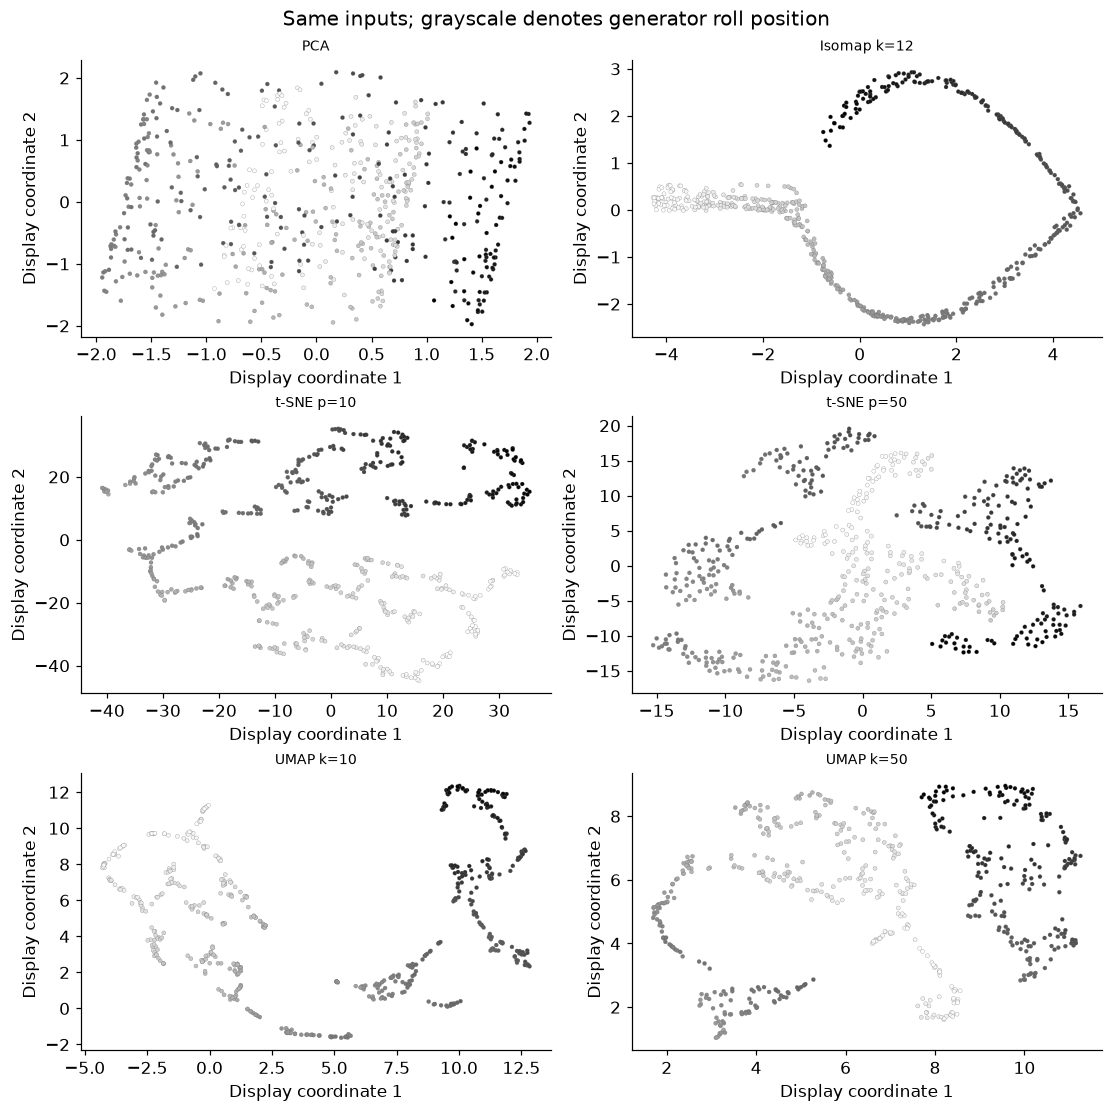

In [2]:
import umap,numba
from sklearn.datasets import make_swiss_roll
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE,Isomap,trustworthiness
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances
from sklearn.cluster import DBSCAN
from scipy.stats import spearmanr
numba.set_num_threads(1);VERSIONS.update(umap=umap.__version__,numba=numba.__version__)
raw,intrinsic=make_swiss_roll(600,noise=.05,random_state=SEED);scaler=StandardScaler().fit(raw);x=scaler.transform(raw)
pairs=rng.integers(0,600,(1000,2));pairs=pairs[pairs[:,0]!=pairs[:,1]]
original_dist=pairwise_distances(x);near=np.argsort(original_dist,axis=1)[:,1:11]
constructors={'PCA':PCA(2,svd_solver='full'),'Isomap k=12':Isomap(n_components=2,n_neighbors=12,eigen_solver='dense',n_jobs=1),'t-SNE p=10':TSNE(2,perplexity=10,max_iter=500,init='pca',learning_rate='auto',random_state=SEED,n_jobs=1),'t-SNE p=50':TSNE(2,perplexity=50,max_iter=500,init='pca',learning_rate='auto',random_state=SEED,n_jobs=1),'UMAP k=10':umap.UMAP(n_neighbors=10,min_dist=.1,n_epochs=200,random_state=SEED,transform_seed=SEED,n_jobs=1,low_memory=True),'UMAP k=50':umap.UMAP(n_neighbors=50,min_dist=.1,n_epochs=200,random_state=SEED,transform_seed=SEED,n_jobs=1,low_memory=True)}
embeddings={};rows=[]
for name,model in constructors.items():
    z=model.fit_transform(x);embeddings[name]=z;distance=pairwise_distances(z);neighbors=np.argsort(distance,axis=1)[:,1:11]
    recall=float(np.mean([len(set(a)&set(b))/10 for a,b in zip(near,neighbors)]))
    labels=DBSCAN(eps=.3,min_samples=5).fit_predict(StandardScaler().fit_transform(z))
    rows.append({'method':name,'trustworthiness':float(trustworthiness(x,z,n_neighbors=10)),'neighbor_recall':recall,'pair_rank_correlation':float(spearmanr(original_dist[pairs[:,0],pairs[:,1]],distance[pairs[:,0],pairs[:,1]]).statistic),'display_groups':int(len(set(labels)-{-1})),'display_noise_fraction':float(np.mean(labels==-1))})
    assert np.isfinite(z).all() and z.shape==(600,2)
new_raw,_=make_swiss_roll(20,noise=.05,random_state=SEED+1);new_z=constructors['UMAP k=10'].transform(scaler.transform(new_raw))
assert new_z.shape==(20,2) and np.isfinite(new_z).all()
assert not hasattr(constructors['t-SNE p=10'],'transform')
RESULTS.update(metrics=rows,new_umap_shape=list(new_z.shape),pair_count=len(pairs),cohort_size=600)
display(pd.DataFrame(rows))
fig,axes=plt.subplots(3,2,figsize=(10,10))
for ax,(name,z) in zip(axes.flat,embeddings.items()):
    ax.scatter(z[:,0],z[:,1],c=intrinsic,cmap='Greys',s=7,edgecolors='.4',linewidths=.15);ax.set(title=name,xlabel='Display coordinate 1',ylabel='Display coordinate 2')
fig.suptitle('Same inputs; grayscale denotes generator roll position');plt.show()


<a id="diagnostics"></a>
 ## Attractive geometry is not a validation set
 Display group counts come from the same arbitrary DBSCAN rule after per-display scaling. They do not establish real regimes or faults. Global input-distance rank correlation can penalize useful unrolling, because rolled Euclidean distance differs from manifold distance. UMAP offers a fitted transform for new observations; that contract still requires checking new-data compatibility. This sklearn t-SNE estimator has no transform method. Execution uses UMAP 0.5.12, while the inspected live documentation identifies itself as 0.5.8.


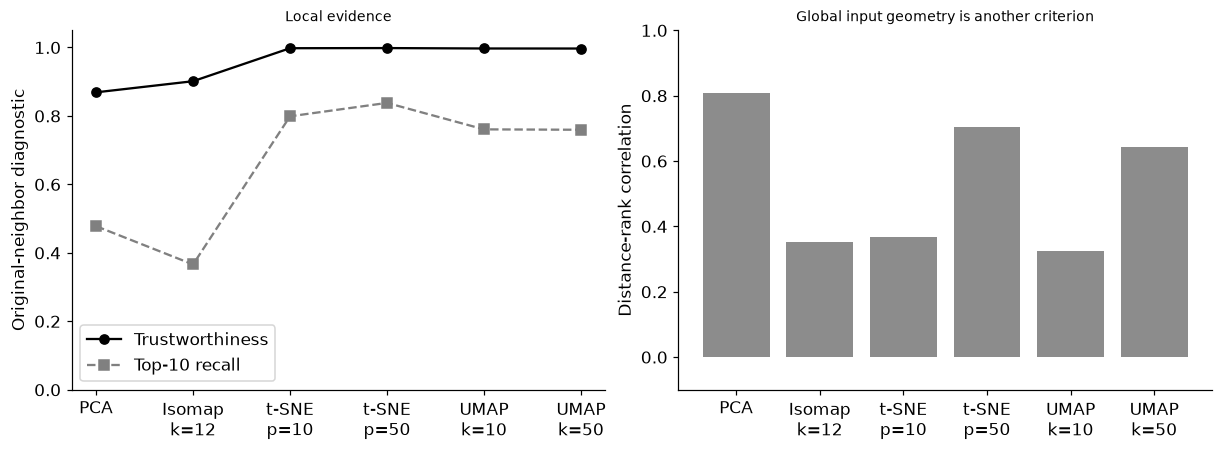

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
xx=np.arange(len(rows))
axes[0].plot(xx,[r['trustworthiness'] for r in rows],'o-',color='black',label='Trustworthiness')
axes[0].plot(xx,[r['neighbor_recall'] for r in rows],'s--',color='.5',label='Top-10 recall')
axes[0].set(xticks=xx,xticklabels=[r['method'].replace(' ','\n',1) for r in rows],ylim=(0,1.05),ylabel='Original-neighbor diagnostic',title='Local evidence');axes[0].legend()
axes[1].bar(xx,[r['pair_rank_correlation'] for r in rows],color='.55');axes[1].set(xticks=xx,xticklabels=[r['method'].replace(' ','\n',1) for r in rows],ylim=(-.1,1),ylabel='Distance-rank correlation',title='Global input geometry is another criterion');plt.show()
assert all(0<=r['neighbor_recall']<=1 for r in rows)


In [4]:
summary={'example_id':'code_099','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual t-SNE and UMAP', 'neighborhood diagnostics', 'transductive visualization', 'new-query transforms'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual t-SNE and UMAP", "neighborhood diagnostics", "transductive visualization", "new-query transforms"], "elapsed_seconds": 7.325, "example_id": "code_099", "hardware": "Darwin arm64 CPU", "results": {"cohort_size": 600, "metrics": [{"display_groups": 2, "display_noise_fraction": 0.0016666666666666668, "method": "PCA", "neighbor_recall": 0.47783333333333333, "pair_rank_correlation": 0.8086182648355413, "trustworthiness": 0.8688685486170515}, {"display_groups": 1, "display_noise_fraction": 0.0, "method": "Isomap k=12", "neighbor_recall": 0.366, "pair_rank_correlation": 0.3533513895860874, "trustworthiness": 0.9013416025092672}, {"display_groups": 3, "display_noise_fraction": 0.0, "method": "t-SNE p=10", "neighbor_recall": 0.7988333333333333, "pair_rank_correlation": 0.36630214623002333, "trustworthiness": 0.9977644710578842}, {"display_groups": 2, "display_noise_fraction": 0.0, "method": "t-SNE p=50", "neighbor_recall": 0.838000000000